# **House Price Prediction Project using Machine Learning in Python**

## **Project Overview**




<br>

![image](https://images.pexels.com/photos/8732777/pexels-photo-8732777.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=1)

<br>


Zillow has tasked us with the challenge of predicting the log-error between their Zestimate and the actual sale price of properties, leveraging all available features. This
logerror, is calculated using the following formula:

logerror = log(Zestimate) − log(SalePrice)- log(SalePrice)

and it is recorded in the transactions file train.csv.

This metric is crucial for assessing the accuracy of Zillow's estimates against real-world sales data, and it's logged in the transactions file train.csv.

Zestimates, Zillow's estimated home values, are derived from a sophisticated ensemble of 7.5 million statistical and machine learning models, which analyze numerous data points for each property. Over time, Zillow has significantly enhanced the accuracy of these estimates, reducing the median margin of error from 14% initially to just 5% today. This evolution has solidified Zillow's position as one of the largest and most trusted real estate marketplaces in the United States, setting a benchmark for impactful machine learning applications in the industry.

In this data science project, our objective is to develop a robust machine learning algorithm capable of accurately predicting the log-error between Zestimates and actual sale prices. This task presents an exciting opportunity to leverage advanced modeling techniques and domain knowledge to enhance the performance and reliability of Zillow's estimation process.

## **Who is this notebook intended for?**

Regression is one of the foundational techniques in Machine Learning. Being one of the
most well-understood algorithms, beginners need some help to understand
fundamental terminology related to regression.

<br>

![student](https://img.freepik.com/premium-vector/man-working-with-laptop-cartoon-illustration-labour-day-concept-white-isolated-flat-cartoon-style_75802-203.jpg?w=400)

The notebook is intended for data analysts, data scientists, and machine learning enthusiasts who are interested in gaining a better understanding of their regression. This notebook is designed for individuals who are familiar with Python and have some knowledge of machine learning concepts.






## **Learning Outcomes**

* Understanding the business problem
* Importing the dataset and required libraries
* Performing basic Exploratory Data Analysis (EDA)
* Data cleaning and missing data handling if required, using appropriate methods
* Checking data distribution using statistical techniques
* Checking for outliers and how they need to be treated as per the model selection
* Using python libraries such as matplotlib and seaborn for data interpretation and advanced visualizations
* Splitting Dataset into Train and Test using various sampling techniques
* Performing Feature Engineering on sample data for better performance
* Training a model using Regression techniques like Linear Regression, Random Forest Regressor, XGBoost Regressor, etc
* Training multiple models using different Machine Learning Algorithms suitable for the scenario and checking for best performance
* Understanding feature scaling importance and applying them if required
* Performing Cross-Validation to check if the model is overfitting and whether results are somewhat constant
* Tuning hyperparameters of models to achieve optimal performance
* Making predictions using the trained model
* Gaining confidence in the model using metrics such as MAE, MSE, RMSE
* What features are most helpful for predictive power using Feature Importance
* How Target variable is dependent on the values of Input features

* Selection of the best model based on performance metrics and HyperParameter Optimization

## **Execution Instructions**
<br>

### Running on your computer locally

To run the notebook on your local system set up a [python](https://www.python.org/) environment. Set up the [jupyter notebook](https://jupyter.org/install) with python or by using [anaconda distribution](https://anaconda.org/anaconda/jupyter). Download the notebook and open a jupyter notebook to run the code on local system.

The notebook can also be executed by using [Visual Studio Code](https://code.visualstudio.com/), and [PyCharm](https://www.jetbrains.com/pycharm/).
<br>
<br>







## **Approach**

Model Building

* Performing train test split

* Feature Scaling

* Dropping features if necessary

* Linear Regression Model

* Elastic Net

* Ridge Regression

* Lasso Regressor

* XGBoost Regressor

* Adaboost Regressor

* Gradient Boosting Regressor

* Decision Tree Regressor

* Random Forest Regressor




Model Validation

* Mean Absolute Error


Hyperparameter Tuning (GridSearchCV)

* For Random Forest Regressor


Checking for Feature Importance
<br>

Creating the final model and making predictions



## **Important Libraries**

* **pandas**: pandas is a fast, powerful, flexible, and easy-to-use open-source data analysis and manipulation tool built on top of the Python programming language. Refer to [documentation](https://pandas.pydata.org/) for more information.

* **NumPy**: The fundamental package for scientific computing with Python. Fast and versatile, the NumPy vectorization, indexing, and broadcasting concepts are the de-facto standards of array computing today. NumPy offers comprehensive mathematical functions, random number generators, linear algebra routines, Fourier transforms, and more. Refer to [documentation](https://numpy.org/) for more information. pandas and NumPy are together used for most of the data analysis and manipulation in Python.

* **Matplotlib**: Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python. Refer to [documentation](https://matplotlib.org/) for more information.

* **seaborn**: Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics. Refer to [documentation](https://seaborn.pydata.org/) for more information.

* **scikit-learn**: Simple and efficient tools for predictive data analysis
accessible to everybody and reusable in various contexts.
It is built on NumPy, SciPy, and matplotlib to support machine learning in Python. Refer to [documentation](https://scikit-learn.org/stable/) for more information.

### **Model Creation:**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import xgboost

from math import sqrt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

%matplotlib inline
pd.set_option('display.max_columns',None)
warnings.simplefilter(action='ignore')

### Load Data:

In [ ]:
df = pd.read_csv('final_zillow_dataset.csv')
df.shape

(70260, 21)

In [ ]:
df.head()

,parcelid,bathroomcnt,bedroomcnt,buildingqualitytypeid,finishedsquarefeet12,fips,heatingorsystemtypeid,latitude,longitude,lotsizesquarefeet,propertylandusetypeid,rawcensustractandblock,regionidcity,regionidcounty,regionidzip,roomcnt,unitcnt,taxamount,logerror,yeardifference,propertyzoningdesc_labels
0,10726315,3.0,3.0,4.0,2445.0,6037.0,2.0,34.184300,-118.657000,63878.0,266.0,60.371352,12447.0,3101.0,96389.0,0.0,1.0,7170.22,0.0383,33.0,627
1,10727091,2.0,3.0,7.0,1160.0,6037.0,2.0,34.188121,-118.646361,7688.0,261.0,60.371352,12447.0,3101.0,96342.0,0.0,1.0,5421.96,0.0030,55.0,638
2,10730788,2.0,4.0,7.0,1570.0,6037.0,2.0,34.188446,-118.616724,11308.0,261.0,60.371351,12447.0,3101.0,96342.0,0.0,1.0,5097.78,-0.0020,56.0,638
3,10735394,3.0,4.0,4.0,2863.0,6037.0,2.0,34.171439,-118.646883,16376.0,261.0,60.371373,12447.0,3101.0,96389.0,0.0,1.0,7475.21,0.0129,52.0,632
4,10743512,3.0,2.0,4.0,1394.0,6037.0,2.0,34.152890,-118.791494,77543.0,269.0,60.378003,34278.0,3101.0,96385.0,0.0,1.0,5550.36,0.0630,17.0,769


## **Train - Test Split**

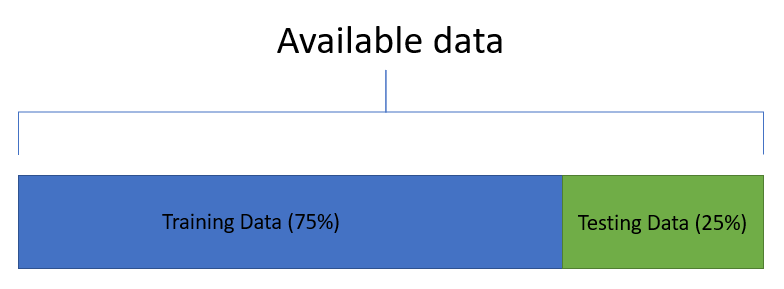


The data points are divided into two datasets, train and test, in a train test split method. The train data is used to train the model, and the model is then used to predict on the test data to see how the model performs on unseen data and whether it is overfitting or underfitting.

<br>



### **Underfitting and Overfitting**

* **Underfitting**: Underfitting occurs when a statistical model or machine learning algorithm fails to capture the underlying trend of the data, i.e., it performs well on training data but poorly on testing data. Its occurrence merely indicates that our model or method does not adequately suit the data. It frequently occurs when we select a simpler model yet the data contains complicated non-linear patterns or when there is insufficient data to develop a linear model. The obvious approach is to build a complex model or increase the number of linear features in the data.

* **Overfitting**: When a statistical model fails to produce correct predictions on testing data, it is said to be overfitted. When a model is trained with a large amount of data, it begins to learn from the noise and incorrect data entries in our data set. It usually occurs when we build a complex model on a simpler dataset.
An overfitted model performs well on training data because it has memorized the patterns in the data, but it performs poorly on testing data. An under-fitted model, on the other hand, will perform worse on both datasets because it is unable to capture the trends and patterns underlying the dataset when training.

<br>





In [ ]:
X = df.drop('logerror', axis=1)
y = df['logerror']
new_df = df.copy()
X.shape, y.shape

((70260, 20), (70260,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state = 100)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((52695, 20), (52695,), (17565, 20), (17565,))

### Feature Scaling:

In [ ]:
train_vars = [var for var in X_train.columns if var not in ['parcelid', 'logerror']]
len(train_vars)

19

In [ ]:
scaler = StandardScaler()

scaler.fit(X_train[train_vars])

X_train[train_vars] = scaler.transform(X_train[train_vars])

X_test[train_vars] = scaler.transform(X_test[train_vars])

In [ ]:
X_train.head()

,parcelid,bathroomcnt,bedroomcnt,buildingqualitytypeid,finishedsquarefeet12,fips,heatingorsystemtypeid,latitude,longitude,lotsizesquarefeet,propertylandusetypeid,rawcensustractandblock,regionidcity,regionidcounty,regionidzip,roomcnt,unitcnt,taxamount,yeardifference,propertyzoningdesc_labels
15602,10934030,1.039614,1.077319,-1.450606,1.368148,-0.672408,-0.526789,0.533872,-0.840819,-0.282457,-0.50568,-0.703341,-0.813301,0.672408,-1.208086,-0.439343,-0.081247,-0.954568,1.254891,-0.470974
27292,12116223,-1.441419,0.059583,0.629159,0.535918,-0.672408,-0.526789,0.674431,-0.036819,-0.267228,-0.50568,-0.671488,0.974128,0.672408,-0.604150,-0.439343,-0.081247,-0.737606,2.552634,1.686830
37134,11533593,-0.200903,0.059583,0.629159,-0.728171,-0.672408,1.921281,0.016094,-1.104821,-0.334003,-0.50568,-0.690187,-0.813301,0.672408,-1.213056,-0.439343,-0.081247,1.636555,0.779052,-0.470974
19660,13078527,-0.200903,1.077319,0.629159,-0.591716,-0.672408,-0.526789,0.122551,0.902323,-0.274704,-0.50568,-0.677385,0.333907,0.672408,-0.032524,-0.439343,-0.081247,-0.229807,0.173439,2.541898
19926,12163237,-0.200903,-0.958153,0.629159,-0.860129,-0.672408,-0.526789,0.764055,-0.126408,-0.311506,-0.50568,-0.671698,0.103886,0.672408,-0.671254,-0.439343,-0.081247,-0.688036,1.903762,0.161445


### Dropping parcelid:

In [ ]:
X_train_new = X_train.copy()
X_test_new = X_test.copy()

X_train.drop(columns='parcelid', axis=1, inplace=True)
X_test.drop(columns='parcelid', axis=1, inplace=True)

## **Multiple Linear Regression**


Linear regression, often known as simple regression, creates a relationship between two variables. Linear regression is represented visually as a straight line, with the slope determining how a change in one variable affects a change in the other. A linear regression relationship's y-intercept reflects one variable's value when the other's value is 0.

Multiple linear regression estimates the relationship between two or more independent variables and one dependent variable.
$$\hat y = \beta_0+\beta_1x_1+\dots \beta_px_p+\epsilon$$

where $p$ is... number of features in the model.

* For any given independent variable (x) value, y is the dependent variable's predicted value for the dependent variable (y).
* $\beta_0$ represents the intercept, or the predicted value of y, when x is 0.
* $\beta_1$ is the regression coefficient of variable $x_1$, which tells us how much y will change as $x_1$ increases or decreases.
* $\beta_p$is the regression coefficient of the last variable $x_p$, which tells us how much y will change as $x_p$ increases or decreases.
* $x_1$ ... $x_p$ are the independent or predictor variables that help us predict y
* $\epsilon$ is the error left due to the incorrect calculation of the regression coefficients.


To understand the basics of Linear Regression, cost function and least squares, refer to the [Linear Regression Model Project in Python for Beginners Part 1 Notebook](https://s3.amazonaws.com/projex.dezyre.com/fundamentals-simple-linear-regression-python-beginners/materials/regression_part_1.ipynb) where Simple Linear Regression and the mathematics behind it have been explained in detail.




## **Linear Regression with Gradient Descent**


Gradient descent is an optimization algorithm that is commonly used in machine learning to find the parameters (weights and biases) that minimize the cost function of a model. In the context of linear regression, the goal is to find the values of the weight vector (W) and the bias term (b) that best fit the training data.

The basic idea of gradient descent is to iteratively update the weights and biases in the direction of the negative gradient of the cost function with respect to the weights and biases. The gradient is simply the vector of partial derivatives of the cost function with respect to each weight and bias. By taking steps in the direction of the negative gradient, the algorithm can gradually minimize the cost function.

The steps involved in gradient descent are as follows:

* Initialize the weight vector (W) and the bias term (b) to small random values.

* Calculate the predicted values (y_hat) for the training data using the current values of the weight vector and the bias term.

* Calculate the error (E) between the predicted values and the actual values of the training data.

* Calculate the gradient of the cost function with respect to the weight vector and the bias term using the error calculated in step 3.

* Update the weight vector and the bias term by taking a step in the direction of the negative gradient using the learning rate (alpha).

* Repeat steps 2-5 until the cost function converges to a minimum.

Given a cost function J and a set of parameters (W,b), the gradient of J with respect to the parameters can be calculated using partial derivatives



$$J(w) = \frac{1}{2n} \sum_{i=1}^{n} (h_w(x^{(i)}) - y^{(i)})^2$$

where $w$ is a vector of the model parameters, $n$ is the number of training examples, $x^{(i)}$ is the feature vector of the $i$-th example, $y^{(i)}$ is the corresponding target value, and $h_w(x)$ is the predicted value for $x$ using the model parameters $w$.

The goal of gradient descent is to find the values of $w$ that minimize the cost function $J(w)$. The algorithm starts with an initial guess for $w$ and iteratively updates it using the following rule:

$$w_j = w_j - \alpha \frac{\partial J(w)}{\partial w_j}$$

where $\alpha$ is the learning rate, which controls the step size of each update, and $\frac{\partial J(w)}{\partial w_j}$ is the partial derivative of $J(w)$ with respect to the $j$-th parameter.

In the case of linear regression, the partial derivative is:

$$\frac{\partial J(w)}{\partial w_j} = \frac{1}{n} \sum_{i=1}^{n} (h_w(x^{(i)}) - y^{(i)})x_j^{(i)}$$

This means that the update rule for $w_j$ becomes:

$$w_j = w_j - \alpha \frac{1}{n} \sum_{i=1}^{n} (h_w(x^{(i)}) - y^{(i)})x_j^{(i)}$$

The algorithm continues to update $w$ until the cost function $J(w)$ converges to a minimum value or until a maximum number of iterations is reached. The learning rate $\alpha$ is a hyperparameter that needs to be tuned to ensure that the algorithm converges to the minimum value in a reasonable amount of time.





## **Errors in Regression**

The regression line regress towards the mean to create the best fit which essentially means that the errors are at the lowest. In the above plot, it is visible that the regression line is not able to exactly predict the true values. There is always going to be some space for errors.

Let's understand the various errors in Regression:


* The mean absolute error (MAE) is the most basic regression error statistic to grasp. We'll compute the residual for each data point individually, using only the absolute value of each so that negative and positive residuals don't cancel out. The average of all these residuals is then calculated. MAE essentially describes the typical magnitude of the residuals. <br>
$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y-\hat y|$$

* The mean square error (MSE) is identical to the mean absolute error (MAE) but squares the difference before aggregating all of them. The MSE will nearly always be greater than the MAE because we are squaring the difference. Because of this, we are unable to directly compare the MAE and MSE. We are limited to comparing the error metrics of our model to those of a rival model. The presence of outliers in our data makes the square term's impact on the MSE equation very clear. In MAE, each residual adds proportionally to the overall error, whereas in MSE, the error increases quadratically. As a result, our data outliers will ultimately result in a considerably bigger total error in the MSE than they will in the MAE. Similarly to this, our model will suffer more if it predicts values that are significantly different from the matching actual value.
This means that in MSE as opposed to MAE, substantial disparities between actual and predicted values are punished more severely. <br>If we wish to limit the importance of outliers, we should use MAE because outlier residuals do not contribute as much to overall error as MSE. Finally, the decision between MSE and MAE is application-specific and depends on how large errors need to be handled.

$$MSE= \frac{1}{n}\sum_{i=1}^{n}(y-\hat y)^2$$


* The root mean squared error (RMSE) is another error statistic you may come upon. It is the square root of the MSE, as the name implies. Because the MSE is squared, its units differ from the original output. RMSE is frequently used to transform the error metric back into comparable units, making interpretation easier. Outliers have a comparable effect on the MSE and RMSE because they both square the residual.

$$RMSE= \sqrt(\frac{1}{n}\sum_{i=1}^{n}(y-\hat y)^2)$$


* The percentage counterpart of MAE is the mean absolute percentage error (MAPE). Just as MAE is the average amount of error created by your model, MAPE is the average distance between the model's predictions and their associated outputs. MAPE, like MAE, has a clear meaning because percentages are easier for people to understand. Because of the use of absolute value, MAPE and MAE are both resistant to the effects of outliers.

$$MAPE= \frac{100\%}{n}\ \sum_{i=1}^{n}\left| \frac{y-\hat y}{y} \right|$$

### **Model Comparisons**

* $R^2$: The $R^2$ or the coefficient of determination is the proportion of the variance in the dependent variable that is explained from the independent variable(s). $R^2$ is expressed between 0 and 1 for the level of variance explained.
As we learned in the previous section, the ratio $\frac{SSE}{TSS}$ should be low for a robust model, this ratio signifies the error or unexplained variance by the independent variable(s).
Mathematically, $R^2$ or explained variance can be expressed as:

$$ R^2 = 1 - \frac{SSE}{TSS} $$

* Adjusted $R^2$: For linear models, adjusted $R^2$ is a corrected goodness-of-fit statistic. It determines the proportion of variance in the target field explained by the input or inputs.
$R^2$ tends to overestimate the goodness-of-fit of the linear regression. It always grows as the number of independent variables in the model grows.
It happens because we tend to deduct a large amount (due to multiple variables) to calculate error as the number of independent variables increases. Hence, the ratio $\frac{SSE}{TSS}$ is even lower than it should be and  $R^2$ seems to be high but it might not be an appropriate model for production data. It is adjusted to account for this overestimation. Considering N as the total sample size and p as the number of independent variables, adjusted $R^2$ can be expressed as:

$$ \text{Adjusted }  R^2 = 1 - \frac{(1 - R^2)(N - 1)}{N - p - 1} $$

## **Regularization**

Before moving further ahead in the topic of Regularization, let us understand Underfitting and Overfitting properly.

* **Underfitting**: Underfitting occurs when a statistical model or machine learning algorithm fails to capture the underlying trend of the data, i.e., it performs well on training data but poorly on testing data. Its occurrence merely indicates that our model or method does not adequately suit the data. It frequently occurs when we select a simpler model yet the data contains complicated non-linear patterns or when there is insufficient data to develop a linear model. The obvious approach is to build a complex model or increase the number of linear features in the data.

* **Overfitting**: When a statistical model fails to produce correct predictions on testing data, it is said to be overfitted. When a model is trained with a large amount of data, it begins to learn from the noise and incorrect data entries in our data set. It usually occurs when we build a complex model on a simpler dataset.
An overfitted model performs well on training data because it has memorized the patterns in the data, but it performs poorly on testing data. An under-fitted model, on the other hand, will perform worse on both datasets because it is unable to capture the trends and patterns underlying the dataset when training.

**Regularization**

Avoiding overfitting is one of the most important tasks of training your machine learning model. If the model is overfitting, it will not be able to generalise and have a low accuracy in real time scenario. This occurs when your model is trying to grab too much information including the noise from your training dataset. By noise, we mean data points that aren't truly representative of your data's true properties, but are instead random chance. Learning such data points makes your model more adaptable, but it also increases the risk of overfitting. Regularization is a type of regression in which the coefficient estimates are constrained, regularised, or shrunk towards zero. In other words, in order to avoid overfitting, it pushes the model to be more simpler by reducing or shrinking the weights.




**Ridge or L2 Regularization**

In simple linear regression, an optimization function or loss function known as the residual sum of squares is used to create a model that accurately predicts the value of Y. (RSS). With the help of this loss function, the model learns. The difference between the actual value and the expected output is measured using the loss function. The coefficients are chosen that minimise the loss function when applied to the training data. The RSS is changed by adding the shrinkage quantity or a penality factor to the ridge regression. The penalty term in L2 regularisation is equal to the square of the coefficient magnitude so that a greater term is subtracted while updating to new coefficient value using optimization algorithm and a smaller value is achieved.



$$ RSS_{ridge} = \sum_{i=1}^{n} (y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij})^2 + \lambda \sum_{j=1}^{p} \beta_j^2 $$

Here, the additional penalty term $\lambda \sum_{j=1}^{p} \beta_j^2$ is added to the RSS in order to shrink the parameter estimates towards zero, while still allowing some of the information from the original data to remain. The amount of shrinkage is controlled by the tuning parameter $\lambda$, which determines the strength of the penalty. As the $\lambda$ increases, the values of the parameters approaches zero.

**Lasso or L1 Regularization**

On the other hand, L1 regularisation, also known as Lasso Regression, alters the RSS by adding a penalty equal to the absolute value of the weight coefficients.


$$ RSS_{lasso} = \sum_{i=1}^{n} (y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij})^2 + \lambda \sum_{j=1}^{p} |\beta_j| $$

Here, the penalty term $\lambda \sum_{j=1}^{p} |\beta_j|$ forces some of the coefficients to be exactly equal to zero, effectively performing feature selection. The amount of shrinkage is again controlled by the tuning parameter $\lambda$.

**Differences between L1 and L2 Regularization**

* One of the primary differences between L1 and L2 regularization is the way that the penalty is applied to the coefficients. With L1 regularization, the penalty is applied to the absolute value of the coefficient, while with L2 regularization, the penalty is applied to the squared value of the coefficient. This difference in the penalty function means that L1 regularization tends to drive some of the coefficients to exactly zero, effectively performing feature selection, while L2 regularization only shrinks the coefficients towards zero, but does not usually make them exactly zero.

* Another difference between the two types of regularization is that L1 regularization tends to be more robust to outliers, while L2 regularization is more sensitive to them. This is because the L1 penalty is less affected by outliers, since the absolute value of the coefficient is always positive, while the L2 penalty is more influenced by outliers, since the squared value of the coefficient is always positive and grows more quickly than the absolute value as the coefficient becomes larger.

* The choice between L1 and L2 regularization will depend on your specific problem and dataset. In general, L2 regularization is a good default choice, but if you have a large number of features and suspect that many of them may be irrelevant or redundant, L1 regularization may be more effective.

Watch the video [Understanding Ridge and Lasso regression](https://www.projectpro.io/project/hackerday-project/project-title/build%20numpy%20regression%20models#sub-hackerday-video-3) for understanding.

### **How regularization techniques affect machine learning models?**


* The effect of lambda on the model:
Lambda is a tuning parameter that decides the amount of penalty to be added to the model. A small value of lambda may result in underfitting, while a large value may result in overfitting. The optimal value of lambda can be found using cross-validation. (A technique that will be introduced in later projects.)

* Feature selection: Lasso regularization has the unique property of setting some of the feature coefficients to zero, making it an effective feature selection method. Ridge regularization, on the other hand, does not have this property.

* Interpretation of the coefficients: Ridge regularization shrinks the coefficients towards zero, but does not set them exactly to zero. This means that all features contribute to the model to some extent. Lasso regularization, on the other hand, can completely eliminate some features from the model, making it easier to interpret.

### **Why L1 regularization shrinks coefficients to exactly zero?**

The penalty equation for Ridge is of a circle, and the smallest values of the coefficients can lie within that circle only. Since the circle has no sharp points, the contours of the circle will keep the coefficients from touching the axis to achieve the minimum RSS. This means that the values of coefficients achieved by Ridge will never be exactly zero, but rather they will approach zero as the value of $λ$ increases.

On the other hand, Lasso regression uses the L1 norm of the coefficient vector as the penalty term. The penalty equation for Lasso can be represented as $λΣ(|coeff|)$, where $λ$ is the tuning parameter, and the bars denote the absolute value of the coefficients. The L1 penalty equation is of a diamond, and to achieve the minimum RSS, the contours will touch the axis, indicating zero values. This means that Lasso can effectively reduce the number of features used for prediction and also lead to sparse models. Lasso reduces the coefficients to exactly zero, which is useful when trying to identify a subset of features that are important for making accurate predictions.

In summary, L1 regularization (Lasso) can reduce the coefficients to exactly zero, making it useful for feature selection, while L2 regularization (Ridge) only approaches zero as the value of the tuning parameter increases. The difference between the two approaches lies in the shape of their penalty equations. The circular shape of the L2 penalty equation means that the smallest values of the coefficients can only lie within that circle, while the diamond shape of the L1 penalty equation means that the contours can touch the axis, allowing the coefficients to be reduced to zero.





### Linear Regression Model:

In [ ]:
linear_reg = LinearRegression()

linear_reg.fit(X_train, y_train)

LinearRegression()

In [ ]:
linear_reg_pred = linear_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, linear_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, linear_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, linear_reg_pred))))

Mean Absolute Error : 0.05271290201314923

Mean Squared Error : 0.007219676292818219

Root Mean Squared Error : 0.08496867830452713


### Elastic Net Model:

In [ ]:
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)

elastic_net.fit(X_train, y_train)

ElasticNet(alpha=0.1)

In [ ]:
elastic_net_pred = elastic_net.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, elastic_net_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, elastic_net_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, elastic_net_pred))))

Mean Absolute Error : 0.052772037640842616

Mean Squared Error : 0.007263564946868809

Root Mean Squared Error : 0.08522655071554175


### Ridge Regression Model:

In [ ]:
ridge_reg = Ridge(alpha=1, solver='cholesky')

ridge_reg.fit(X_train, y_train)

Ridge(alpha=1, solver='cholesky')

In [ ]:
ridge_reg_pred = ridge_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, ridge_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, ridge_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, ridge_reg_pred))))

Mean Absolute Error : 0.05271298978108195

Mean Squared Error : 0.0072190878626148345

Root Mean Squared Error : 0.08496521560388601


### Lasso Regression Model:

In [ ]:
lasso_reg = Lasso(alpha=0.1)

lasso_reg.fit(X_train, y_train)

Lasso(alpha=0.1)

In [ ]:
lasso_reg_pred = lasso_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, lasso_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, lasso_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, lasso_reg_pred))))

Mean Absolute Error : 0.052772037640842616

Mean Squared Error : 0.007263564946868809

Root Mean Squared Error : 0.08522655071554175


## **Decision Tree**



A decision tree is a non-parametric supervised learning algorithm, which is utilized for both classification and regression tasks. It has a hierarchical, tree structure, which consists of a root node, branches, internal nodes and leaf nodes.


Decision tree learning employs a divide and conquer strategy by conducting a greedy search to identify the optimal split points within a tree. This process of splitting is then repeated in a top-down, recursive manner until all, or the majority of records have been classified under specific class labels. Whether or not all data points are classified as homogenous sets is largely dependent on the complexity of the decision tree. Smaller trees are more easily able to attain pure leaf nodes—i.e. data points in a single class.

However, as a tree grows in size, it becomes increasingly difficult to maintain this purity, and it usually results in too little data falling within a given subtree. When this occurs, it is known as data fragmentation, and it can often lead to overfitting. As a result, decision trees have preference for small trees, which is consistent with the principle of parsimony in Occam’s Razor; that is, “entities should not be multiplied beyond necessity.” Said differently, decision trees should add complexity only if necessary, as the simplest explanation is often the best. To reduce complexity and prevent overfitting, pruning is usually employed; this is a process, which removes branches that split on features with low importance. The model’s fit can then be evaluated through the process of cross-validation.

### **Bagging**



Bagging is an ensemble learning technique that aims to decrease the variance of a single estimator by combining the predictions from multiple learners. The basic idea behind bagging is to generate multiple versions of the training dataset through random sampling with replacement, and then train a separate classifier for each sampled dataset. The predictions from these individual classifiers are then combined using averaging or voting to obtain a final prediction.

**Algorithm:**

Suppose we have a training set D of size n, and we want to train a classifier using bagging. Here are the steps involved:

* Create k different bootstrap samples from D, each of size n.
* Train a classifier on each bootstrap sample.
* When making predictions on a new data point, take the average or majority vote of the predictions from each of the k classifiers.


**Mathematical Explanation:**

Suppose we have a binary classification problem with classes -1 and 1. Let's also assume that we have a training set D of size n, and we want to train a decision tree classifier using bagging.

**Bootstrap Sample**: For each of the k classifiers, we create a bootstrap sample of size n by sampling with replacement from D. This means that each bootstrap sample may contain duplicates of some instances and may also miss some instances from the original dataset. Let's denote the i-th bootstrap sample as D_i.

**Train a Classifier**: We train a decision tree classifier T_i on each bootstrap sample D_i. This gives us k classifiers T_1, T_2, ..., T_k.

**Combine Predictions**: To make a prediction on a new data point x, we take the majority vote of the predictions from each of the k classifiers.

The idea behind bagging is that the variance of the prediction error decreases as k increases. This is because each classifier has a chance to explore a different part of the feature space due to the random sampling with replacement, and the final prediction is a combination of these diverse classifiers.



### **Boosting**

Boosting is a machine learning algorithm that works by combining several weak models (also known as base learners) into a strong model. The goal of boosting is to reduce the bias and variance of the base learners by iteratively adding new models to the ensemble that focus on correcting the errors made by the previous models. In other words, the boosting algorithm tries to learn from the mistakes of the previous models and improve the overall accuracy of the ensemble.

Boosting works by assigning higher weights to the data points that the previous models misclassified, and lower weights to the ones that were classified correctly. This ensures that the new model focuses more on the difficult data points that the previous models struggled with, and less on the ones that were already well-classified. As a result, the new model is more specialized and can improve the accuracy of the ensemble.

There are several types of boosting algorithms, including AdaBoost (Adaptive Boosting), Gradient Boosting, and XGBoost (Extreme Gradient Boosting). Each of these algorithms has its own approach to assigning weights to the data points and building the new models, but they all share the fundamental idea of iteratively improving the accuracy of the ensemble by combining weak models into a strong one. Boosting is a powerful algorithm that has been shown to achieve state-of-the-art results in many machine learning tasks, such as image classification, natural language processing, and recommender systems.









**Difference between Bagging and Boosting**


It's important to remember that boosting is a generic method, not a specific model, in order to comprehend it. Boosting involves specifying a weak model, such as regression or decision trees, and then improving it. In Ensemble Learning, the primary difference between Bagging and Boosting is that in bagging, weak learners are trained in simultaneously, but in boosting, they are trained sequentially. This means that each new model iteration increases the weights of the prior model's misclassified data. This redistribution of weights aids the algorithm in determining which parameters it should focus on in order to increase its performance.

Both the Ensemble techniques are used in a different way as well.  Bagging methods, for example, are often used on poor learners who have large variance and low bias such as decision trees because they tend to overfit, whereas boosting methods are employed when there is low variance and high bias. While bagging can help prevent overfitting, boosting methods are more vulnerable to it because of a simple fact they continue to build on weak learners and continue to minimise error. This can lead to overfitting on the training data but specifying a decent number of models to be generated or hyperparameter tuning,  regularization can help in this case, if overfitting encountered.


## **Bagging vs Boosting**


1. Bagging: It is a homogeneous weak learners’ model that learns from each other independently in parallel and combines them for determining the model average.

![image.png](https://media.geeksforgeeks.org/wp-content/uploads/20210707140912/Bagging.png)


2. Boosting: It is also a homogeneous weak learners’ model but works differently from Bagging. In this model, learners learn sequentially and adaptively to improve model predictions of a learning algorithm.

![image.png](https://media.geeksforgeeks.org/wp-content/uploads/20210707140911/Boosting.png)

Credit: geeksforgeeks

### **Random Forest**


Another way that decision trees can maintain their accuracy is by forming an ensemble via a random forest algorithm; this classifier predicts more accurate results, particularly when the individual trees are uncorrelated with each other.

Random Forest is an ensemble learning algorithm that builds a large number of decision trees and combines them to make a final prediction. It is a type of bagging method, where multiple decision trees are trained on random subsets of the training data and features. The algorithm then averages the predictions of these individual trees to produce a final prediction. Random Forest is particularly useful for handling high-dimensional data and for avoiding overfitting.

**Algorithm of Random Forest**

The algorithm of Random Forest can be summarized in the following steps:

* Start by randomly selecting a subset of the training data, with replacement. This subset is called the bootstrap sample.

* Next, randomly select a subset of features from the full feature set.

* Build a decision tree using the bootstrap sample and the selected subset of features. At each node of the tree, select the best feature and split the data based on the selected feature.

* Repeat steps 1-3 to build multiple trees.

* Finally, combine the predictions of all trees to make a final prediction. For classification, this is usually done by taking a majority vote of the predicted classes. For regression, this is usually done by taking the average of the predicted values.


**Mathematics Behind Random Forest**

The mathematics behind Random Forest involves the use of decision trees and the bootstrap sampling technique. Decision trees are constructed using a recursive binary partitioning algorithm that splits the data based on the values of the selected features. At each node, the algorithm chooses the feature and the split point that maximizes the information gain. Information gain measures the reduction in entropy or impurity of the target variable after the split. The goal is to minimize the impurity of the subsets after each split.

Bootstrap sampling is a statistical technique that involves randomly sampling the data with replacement to create multiple subsets. These subsets are used to train individual decision trees. By using bootstrap samples, the algorithm can generate multiple versions of the same dataset with slightly different distributions. This introduces randomness into the training process, which helps to reduce overfitting.



**Difference between Bagging and Random Forest**

Bagging and Random Forest are both ensemble learning algorithms that involve training multiple models on random subsets of the data. The main difference between the two is the way the individual models are trained.

Bagging involves training multiple models using the bootstrap sampling technique, but each model uses the same set of features. This can lead to correlated predictions, which reduces the variance but not necessarily the bias of the model.

Random Forest, on the other hand, involves training multiple models using the bootstrap sampling technique, but each model uses a randomly selected subset of features. This introduces additional randomness into the model and helps to reduce the correlation between individual predictions. Random Forest can achieve better performance than Bagging, especially when dealing with high-dimensional data or noisy features. In simpler terms it uses subsets of observations as well as features.








## **Adaboost**

AdaBoost, short for Adaptive Boosting, is a popular ensemble learning algorithm that combines multiple weak learners to create a strong predictive model.

In AdaBoost regression, weak regression models, often decision trees with limited depth, are sequentially trained on the dataset. During each iteration, AdaBoost assigns higher weights to data points that were poorly predicted by previous models, thereby focusing subsequent models on the most challenging instances. The final prediction is then obtained by aggregating the predictions of all weak models, weighted by their individual performance. AdaBoost regression is particularly effective in handling nonlinear relationships and can automatically adapt to complex datasets without overfitting. However, it is sensitive to noisy data and outliers, which can adversely affect its performance.

## **Gradient Boosting Trees**

Gradient boosting is a machine learning technique used in regression and classification tasks, among others. It gives a prediction model in the form of an ensemble of weak prediction models, which are typically decision trees.

When a decision tree is the weak learner, the resulting algorithm is called gradient-boosted trees; it usually outperforms random forest. A gradient-boosted trees model is built in a stage-wise fashion as in other boosting methods, but it generalizes the other methods by allowing optimization of an arbitrary differentiable loss function.

Few examples of gradient boosting trees are Xgboost, LightGBM, etc

### XG Boost Regression Model:

In [ ]:
xgb_reg = xgboost.XGBRegressor()

xgb_reg.fit(X_train, y_train)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
             importance_type='gain', interaction_constraints='',
             learning_rate=0.300000012, max_delta_step=0, max_depth=6,
             min_child_weight=1, missing=nan, monotone_constraints='()',
             n_estimators=100, n_jobs=4, num_parallel_tree=1, random_state=0,
             reg_alpha=0, reg_lambda=1, scale_pos_weight=1, subsample=1,
             tree_method='exact', validate_parameters=1, verbosity=None)

In [ ]:
xgb_reg_pred = xgb_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, xgb_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, xgb_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, xgb_reg_pred))))

Mean Absolute Error : 0.05380005751526278

Mean Squared Error : 0.007353353803794397

Root Mean Squared Error : 0.08575169854757629


### Ada Boost Regression Model:

In [ ]:
adaboost_reg = AdaBoostRegressor()

adaboost_reg.fit(X_train, y_train)

AdaBoostRegressor()

In [ ]:
adaboost_reg_pred = adaboost_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, adaboost_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, adaboost_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, adaboost_reg_pred))))

Mean Absolute Error : 0.05676752363007214

Mean Squared Error : 0.0075389292853823555

Root Mean Squared Error : 0.08682700781083243


### Gradient Boosting Regression Model:

In [ ]:
gb_reg = GradientBoostingRegressor()

gb_reg.fit(X_train, y_train)

GradientBoostingRegressor()

In [ ]:
gb_reg_pred = gb_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, gb_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, gb_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, gb_reg_pred))))

Mean Absolute Error : 0.05256208156829912

Mean Squared Error : 0.007179126861416838

Root Mean Squared Error : 0.08472972832139165


### Decision Tree Regressor:

In [ ]:
tree_reg = DecisionTreeRegressor(max_depth=5)

tree_reg.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5)

In [ ]:
tree_reg_pred = tree_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, tree_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, tree_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, tree_reg_pred))))

Mean Absolute Error : 0.05291405344779044

Mean Squared Error : 0.007261957829150837

Root Mean Squared Error : 0.08521712169013242


### Random Forest Regression Model:

In [ ]:
forest_reg = RandomForestRegressor(n_estimators= 500, max_depth=6)

forest_reg.fit(X_train, y_train)

RandomForestRegressor(max_depth=6, n_estimators=500)

In [ ]:
forest_reg_pred = forest_reg.predict(X_test)

print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, forest_reg_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, forest_reg_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, forest_reg_pred))))

Mean Absolute Error : 0.052493979086337225

Mean Squared Error : 0.0071765998987079645

Root Mean Squared Error : 0.08471481510755934


## **Cross Validation & Hyperparameter Optimization:**

Cross-validation and hyperparameter tuning are crucial techniques in machine learning for model evaluation and optimization, respectively. Cross-validation is a method used to assess the performance of a machine learning model by partitioning the dataset into multiple subsets, or folds. The model is trained on a subset of the data and validated on the remaining folds iteratively. This process helps to estimate how well the model will generalize to new, unseen data. Common cross-validation techniques include k-fold cross-validation, stratified k-fold cross-validation, and leave-one-out cross-validation.

On the other hand, hyperparameter tuning is the process of optimizing the hyperparameters of a machine learning algorithm to improve its performance. Hyperparameters are parameters that are set before the learning process begins, such as the learning rate in gradient descent or the depth of a decision tree. Hyperparameter tuning involves searching through a predefined hyperparameter space to find the combination of values that yields the best model performance. Techniques for hyperparameter tuning include grid search, random search, and Bayesian optimization.


### **Grid Search**

Grid search is a hyperparameter tuning technique used to systematically search through a predefined set of hyperparameters to find the combination that yields the best model performance. It works by creating a grid of all possible hyperparameter values and evaluating the model's performance for each combination using cross-validation. Grid search exhaustively explores the entire hyperparameter space, testing every possible combination of hyperparameters specified in the grid. While grid search ensures thorough exploration of the parameter space, it can be computationally expensive, especially for models with a large number of hyperparameters or a wide range of values.

In [ ]:
scores = cross_val_score(forest_reg,
                         X_train,
                         y_train,
                         scoring="neg_mean_squared_error",
                         cv = 5)

In [ ]:
forest_reg_rmse_scores = np.sqrt(-scores)
forest_reg_rmse_scores

array([0.08603316, 0.08501659, 0.08290164, 0.0832188 , 0.08450688])

In [ ]:
param_grid = [
    {'n_estimators': [300, 400, 500], 'max_features': [2, 4, 6]},
    {'bootstrap': [False], 'n_estimators': [300, 400, 500], 'max_features': [2, 4, 6]}
]

forest_regressor = RandomForestRegressor()

grid_search = GridSearchCV(forest_regressor,
                           param_grid,
                           scoring='neg_mean_squared_error',
                           return_train_score=True,
                           cv=3)


In [ ]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=RandomForestRegressor(),
             param_grid=[{'max_features': [2, 4, 6],
                          'n_estimators': [300, 400, 500]},
                         {'bootstrap': [False], 'max_features': [2, 4, 6],
                          'n_estimators': [300, 400, 500]}],
             return_train_score=True, scoring='neg_mean_squared_error')

In [ ]:
grid_search.best_params_

{'max_features': 4, 'n_estimators': 400}

In [ ]:
grid_search.best_estimator_

RandomForestRegressor(max_features=4, n_estimators=400)

In [ ]:
final_predictor = grid_search.best_estimator_
final_predictor.fit(X_train, y_train)
final_pred = final_predictor.predict(X_test)

In [ ]:
print('Mean Absolute Error : {}'.format(mean_absolute_error(y_test, final_pred)))
print()
print('Mean Squared Error : {}'.format(mean_squared_error(y_test, final_pred)))
print()
print('Root Mean Squared Error : {}'.format(sqrt(mean_squared_error(y_test, final_pred))))

Mean Absolute Error : 0.0548705301060865

Mean Squared Error : 0.007400295260520292

Root Mean Squared Error : 0.08602496882022273


### Checking feature importance:

In [ ]:
feature_importances = grid_search.best_estimator_.feature_importances_

attrs = list(df.select_dtypes(include = ['float64','int64']))

sorted(zip(attrs, feature_importances), reverse=True)

[('unitcnt', 0.14040615200665663),
 ('taxamount', 0.09130069345797628),
 ('roomcnt', 0.0015609032588653922),
 ('regionidzip', 0.008357667884179286),
 ('regionidcounty', 0.059049163834885586),
 ('regionidcity', 0.0009523510814962),
 ('rawcensustractandblock', 0.030844984329222235),
 ('propertylandusetypeid', 0.07946690719058498),
 ('parcelid', 0.023641002820564777),
 ('lotsizesquarefeet', 0.008677886840809414),
 ('longitude', 0.1109836767557538),
 ('logerror', 0.048932900132720544),
 ('latitude', 0.11430406832176654),
 ('heatingorsystemtypeid', 0.11542963001723361),
 ('fips', 0.009994615270457963),
 ('finishedsquarefeet12', 0.0010039810716131004),
 ('buildingqualitytypeid', 0.11671937521605583),
 ('bedroomcnt', 0.008630208122532842),
 ('bathroomcnt', 0.029743832386624945)]

### Saving Predictions:

In [ ]:
model_pred = pd.DataFrame({'parcelid':X_test_new.parcelid, 'logerror':final_pred})
model_pred.to_csv('model-predictions.csv',index=False)
model_pred.head()

,parcelid,logerror
11056,11923769,0.018472
20399,14196198,0.005623
51034,12408039,0.004737
41560,10931254,0.021955
69896,14665147,-0.034711


## **Try-it-out**

* Implement other hyperparameter tuning techniques

* Implement tuning techniques on other models

## **Interview Questions**


* What are decision trees? How does the model decide on the split?
* What is boostrap aggregation?
* Explain bias and variance in context of boosting and bagging?
* How can you use decision tree for missing value imputation?
* How does regularization work in gradient boosting models?
* Can you describe the working principles of Logistic Regression, Naive Bayes, Support Vector Machines, Random Forest, Light Gradient Boosting, Extreme Gradient Boosting, and Neural Network algorithms?
* How do these algorithms handle different types of data and decision boundaries?
* What are the key hyperparameters that need to be tuned for each algorithm?
* How would you evaluate the performance of each algorithm in a regression problem?
* How would you interpret the results of the evaluation metrics and draw conclusions about the effectiveness of each approach?
* Can you explain the concept of overfitting and how it can impact model performance?



* Is bagging or boosting computationally faster?
* Can you write your own code to calculate RMSE?
* Can you interpret the results of feature importance analysis and communicate the findings to stakeholders?

## **Conclusion**

In conclusion, this house price prediction project involved a comprehensive data analysis and modeling workflow to develop an accurate predictive model for estimating house prices. The project began with importing necessary libraries and reading the dataset, followed by merging two datasets and gaining a thorough understanding through exploratory data analysis (EDA) and data visualization. Feature engineering techniques were then applied, including duplicate value removal, missing value imputation, rescaling of incorrectly scaled data, standardization, encoding of categorical variables, and generating new features where necessary. Furthermore, multi-collinearity was addressed by removing highly correlated features, and outliers were handled appropriately. The modeling phase comprised training various regression models, including Linear Regression, Elastic Net, Ridge Regression, Lasso Regressor, XGBoost Regressor, Adaboost Regressor, Gradient Boosting Regressor, Decision Tree Regressor, and Random Forest Regressor. Model validation was performed using mean absolute error, and hyperparameter tuning was conducted using GridSearchCV, with a focus on Random Forest Regressor. Additionally, feature importance was checked, leading to the creation of the final model and making predictions.